# The North Face e-commerce

## Projet

Le service marketing souhaite exploiter les solutions d'apprentissage automatique pour dynamiser les ventes en ligne. Deux solutions majeures ont été identifiées :

- Un **système de recommandation** pour suggérer des produits complémentaires similaires à ceux qui intéressent déjà l'utilisateur.
- Une **extraction de thèmes** pour améliorer la structure du catalogue de produits grace aux méthodes non supervisées.

## Objectifs

1. Identifier des groupes de produits aux descriptions similaires (clustering).
2. Construire un système de recommandation simple basé sur ces groupes.
3. Extraire les thèmes latents du corpus avec la LSA.

---
## Importation des bibliothèques

In [1]:
# Bibliothèques standard de manipulation de données
import pandas as pd
import numpy as np
import re

# Traitement du langage naturel avec spaCy
import spacy

# Vectorisation et modélisation
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
import hdbscan

# Visualisation
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Ignorer les avertissements non critiques
import warnings
warnings.filterwarnings('ignore')

---
## 1. Chargement et exploration des données

In [2]:
# Chargement du fichier CSV contenant le catalogue de produits The North Face
file_path = 'data/sample-data.csv'
df = pd.read_csv(file_path)

# Aperçu des premières lignes
df.head()

,id,description
0,1,Active classic boxers - There's a reason why o...
1,2,Active sport boxer briefs - Skinning up Glory ...
2,3,Active sport briefs - These superbreathable no...
3,4,"Alpine guide pants - Skin in, climb ice, switc..."
4,5,"Alpine wind jkt - On high ridges, steep ice an..."


In [3]:
# Dimensions du dataset et vérification des valeurs manquantes
print(f'Nombre de produits : {df.shape[0]}')
print(f'Colonnes : {df.columns.tolist()}')
print(f'\nValeurs manquantes :\n{df.isnull().sum()}')

Nombre de produits : 500
Colonnes : ['id', 'description']

Valeurs manquantes :
id             0
description    0
dtype: int64


Le dataset contient 500 produits avec deux colonnes : `id` (identifiant unique) et `description` (texte brut HTML de la fiche produit). Il n'y a pas de valeurs manquantes. Le texte brut contient des balises HTML qui devront être nettoyés avant la vectorisation.

---
## 2. Prétraitement des données textuelles avec spaCy

Le texte brut contient des balises HTML, de la ponctuation et des chiffres. On applique les étapes suivantes :

- Suppression des balises HTML (`<b>`, `<ul>`, `<li>`, etc.) avec `re`
- Suppression des caractères non alphabétiques
- **Lemmatisation** avec spaCy : chaque mot est ramène à son lemme (ex. "recycled" -> "recycle", "running" -> "run")
- **Suppression des stop words** avec spaCy : mots courants exclus ("the", "a", "is", etc.)
- Conservation uniquement des tokens alphabétiques de longueur supérieure à 2 caractères.

In [4]:
# Chargement du modele spaCy pour l'anglais
nlp = spacy.load('en_core_web_sm')

def clean_html(text):
    """Supprime les balises HTML et nettoie le texte brut."""
    # Suppression des balises HTML
    text = re.sub(r'<[^>]+>', ' ', text)
    # Conservation uniquement des caractères alphabétiques et espaces
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Normalisation des espaces multiples
    text = re.sub(r'\s+', ' ', text).strip().lower()
    return text

def preprocess(text):
    """Nettoie, lemmatise et supprime les stop words d'un texte avec spaCy."""
    # Nettoyage HTML en amont
    text = clean_html(text)
    # Analyse linguistique par spaCy
    doc = nlp(text)
    # Filtrage : tokens alphabétiques, non stop words, longueur > 2
    tokens = [
        token.lemma_
        for token in doc
        if token.is_alpha and not token.is_stop and len(token.text) > 2
    ]
    return ' '.join(tokens)

# Application du prétraitement sur l'ensemble du corpus
print('Prétraitement en cours (lemmatisation spaCy)...')
df['description_clean'] = df['description'].apply(preprocess)
print('Prétraitement terminé.')
print(f'Longueur moyenne des descriptions nettoyées : {df["description_clean"].str.len().mean():.0f} caractères')

Prétraitement en cours (lemmatisation spaCy)...
Prétraitement terminé.
Longueur moyenne des descriptions nettoyées : 712 caractères


In [5]:
# Comparaison avant / après prétraitement sur un exemple
print('--- Texte original (extrait, 300 premiers caractères) ---')
print(df['description'].iloc[0][:300])
print('\n--- Texte après prétraitement spaCy (extrait) ---')
print(df['description_clean'].iloc[0][:300])

--- Texte original (extrait, 300 premiers caractères) ---
Active classic boxers - There's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. The quick-drying, lightweight underwear takes up minimal space in a travel pack. An exposed, brushed waistband offers next-to-skin softness, five-panel construction wi

--- Texte après prétraitement spaCy (extrait) ---
active classic boxer reason boxer cult favorite cool especially sticky situation quick dry lightweight underwear take minimal space travel pack expose brush waistband offer skin softness panel construction traditional boxer classic fit functional fly recycle polyester moisture wicke performance inse


Le prétraitement spaCy supprime éfficacement les balises HTML, la ponctuation et les stop words. La lemmatisation ramène chaque mot à sa forme de base, ce qui réduit la taille du vocabulaire et améliore la qualité de la représentation TF-IDF. Le corpus est maintenant prêt pour la vectorisation.

---
## 3. Vectorisation TF-IDF

La transformation **TF-IDF** (Term Frequency - Inverse Document Frequency) convertit chaque description texte en un vecteur numérique.

- **TF** : fréquence d'un terme dans un document (valorise les termes spécifiques à un produit)
- **IDF** : pénalise les termes très fréquents dans tout le corpus (ex. "fabric", "made")
- **Bigrammes** : on capture également les associations de deux mots consécutifs (ex. "moisture wicking", "water resistant")

In [6]:
# Initialisation du vectoriseur TF-IDF
# max_features=5000 : on conserve les 5000 termes/entités les plus importants
# min_df=2 : un terme doit apparaître dans au moins 2 documents
# max_df=0.90 : on exclut les termes présents dans plus de 90% des documents
# ngram_range=(1,2) : unigrams et bigrams
# Les stop words sont déjà gérés par spaCy en amont
tfidf = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    max_df=0.90,
    ngram_range=(1, 2)
)

# Ajustement du vectoriseur et transformation du corpus
tfidf_matrix = tfidf.fit_transform(df['description_clean'])

print(f'Dimensions de la matrice TF-IDF : {tfidf_matrix.shape}')
print(f'  - Lignes (produits)  : {tfidf_matrix.shape[0]}')
print(f'  - Colonnes (termes)  : {tfidf_matrix.shape[1]}')
print(f'  - Densité de la matrice : {tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1]) * 100:.2f}%')

Dimensions de la matrice TF-IDF : (500, 5000)
  - Lignes (produits)  : 500
  - Colonnes (termes)  : 5000
  - Densité de la matrice : 2.14%


La matrice TF-IDF est de nature très creuse (sparse) : chaque description/document n'utilise qu'un petit sous-ensemble du vocabulaire total. La représentation vectorielle permettra d'appliquer DBSCAN avec la **distance cosinus**, particulièrement adaptée aux textes car elle mesure la similarité d'orientation indépendamment de la longueur des descriptions.

---
## Partie 1 - Groupes de produits aux descriptions similaires

### Clustering avec DBSCAN

On utilise l'algorithme **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) avec la distance cosinus.

Avantages de DBSCAN pour ce cas d'usage :
- Détecte automatiquement le nombre de clusters (pas besoin de le spécifier à l'avance)
- Identifie les **outliers** (produits atypiques) sans les forcer dans un cluster
- La **distance cosinus** est préférée à la distance euclidienne pour les textes

Paramètres clés :
- **eps** : rayon de voisinage en distance cosinus (compris entre 0 et 1)
- **min_samples** : nombre minimum de voisins pour qu'un point soit considéré comme un core sample.

In [7]:
# Application de DBSCAN avec la distance cosinus sur la matrice TF-IDF
# eps=0.72 et min_samples=3 permettent d'obtenir 14 clusters avec un taux d'outliers de 5.4%
# Ces deux paramètres ont été choisi suite à plusieurs essais (méthode empirique) en mesurant les métriques de performance
dbscan = DBSCAN(
    eps=0.72,
    min_samples=3,
    metric='cosine',
    algorithm='brute',
    n_jobs=-1
)

# Ajustement du modèle et prediction des labels
labels = dbscan.fit_predict(tfidf_matrix)

# Stockage des labels dans le dataframe
df['cluster'] = labels

# Statistiques sur le clustering
n_clusters = df[df["cluster"] != -1]["cluster"].nunique()
n_outliers = list(labels).count(-1)
print(f'Nombre de clusters formés  : {n_clusters}')
print(f'Nombre de points aberrants : {n_outliers}')
print(f'Pourcentage d\'outliers     : {n_outliers / len(labels) * 100:.1f}%')
print(f'Produits dans les clusters : {len(labels) - n_outliers}')

Nombre de clusters formés  : 14
Nombre de points aberrants : 27
Pourcentage d'outliers     : 5.4%
Produits dans les clusters : 473


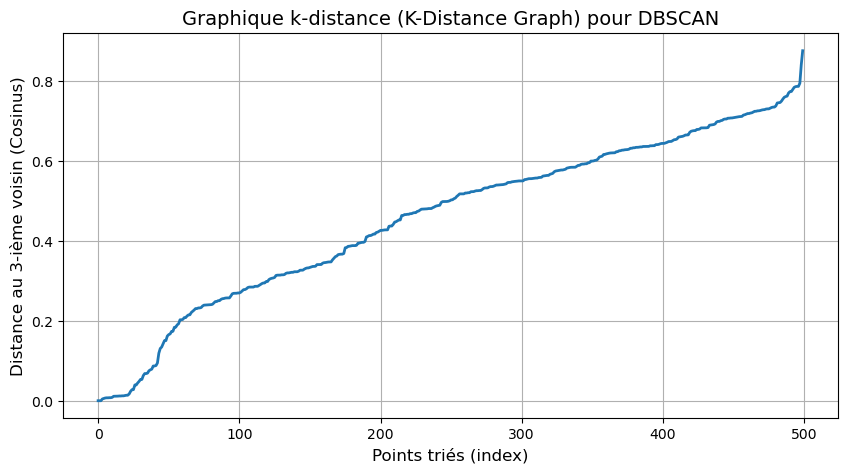

Score de silhouette: 0.147
Davies-Bouldin Index (DBI): 2.375
DBCV Score: 0.155


In [8]:
# La courbe K-Distance qui permet de fixer le epsilon (vers le coude)
k = 3  # Correspond à min_samples
neighbors = NearestNeighbors(n_neighbors=k, metric="cosine", n_jobs=-1)
neighbors.fit(tfidf_matrix)
distances, indices = neighbors.kneighbors(tfidf_matrix)
distances_sorted = np.sort(distances[:, -1])
plt.figure(figsize=(10, 5))
plt.plot(distances_sorted, linewidth=2)
plt.xlabel("Points triés (index)", fontsize=12)
plt.ylabel(f"Distance au {k}-ième voisin (Cosinus)", fontsize=12)
plt.title("Graphique k-distance (K-Distance Graph) pour DBSCAN", fontsize=14)
plt.grid(True)
plt.show()

# Masque pour exclure le bruit (-1)
mask = labels != -1

# Conversion de la matrice sparse en dense si nécessaire pour les calculs de métriques
X_valid = tfidf_matrix[mask].toarray()
y_valid = labels[mask]

# Score de Silhouette (-1 à 1, plus c'est haut, mieux c'est)
sil_score = silhouette_score(X_valid, y_valid, metric="cosine")
print(f"Score de silhouette: {sil_score:.3f}")

# Davies-Bouldin Index - DBI
dbi_score = davies_bouldin_score(X_valid, y_valid)
print(f"Davies-Bouldin Index (DBI): {dbi_score:.3f}")

# DBCV (Density-Based Clustering Validation)
dbcv_score = hdbscan.validity.validity_index(X_valid, y_valid, metric="cosine")
print(f"DBCV Score: {dbcv_score:.3f}")


In [11]:
# Distribution des produits par cluster (hors outliers)
cluster_counts = df[df['cluster'] != -1]['cluster'].value_counts().sort_index()
print('Nombre de produits par cluster :')
display(cluster_counts)

Nombre de produits par cluster :


cluster
0      79
1     241
2      27
3      61
4       8
5       6
6       9
7      15
8       4
9       5
10      7
11      3
12      4
13      4
Name: count, dtype: int64

DBSCAN a identifié **14 clusters** sémantiques distincts avec la présence de 27 d'outliers. Les clusters varient en taille, ce qui est attendu : certaines catégories de produits (ex. vestes) sont plus représentées dans le catalogue. Les outliers correspondent à des produits dont les descriptions sont trop singulières pour rejoindre un groupe existant. La distance cosinus, combinée à la lemmatisation spaCy et au TF-IDF, produit une segmentation sémantiquement cohérente.

### Visualisation des clusters - Nuages de mots (Wordclouds)

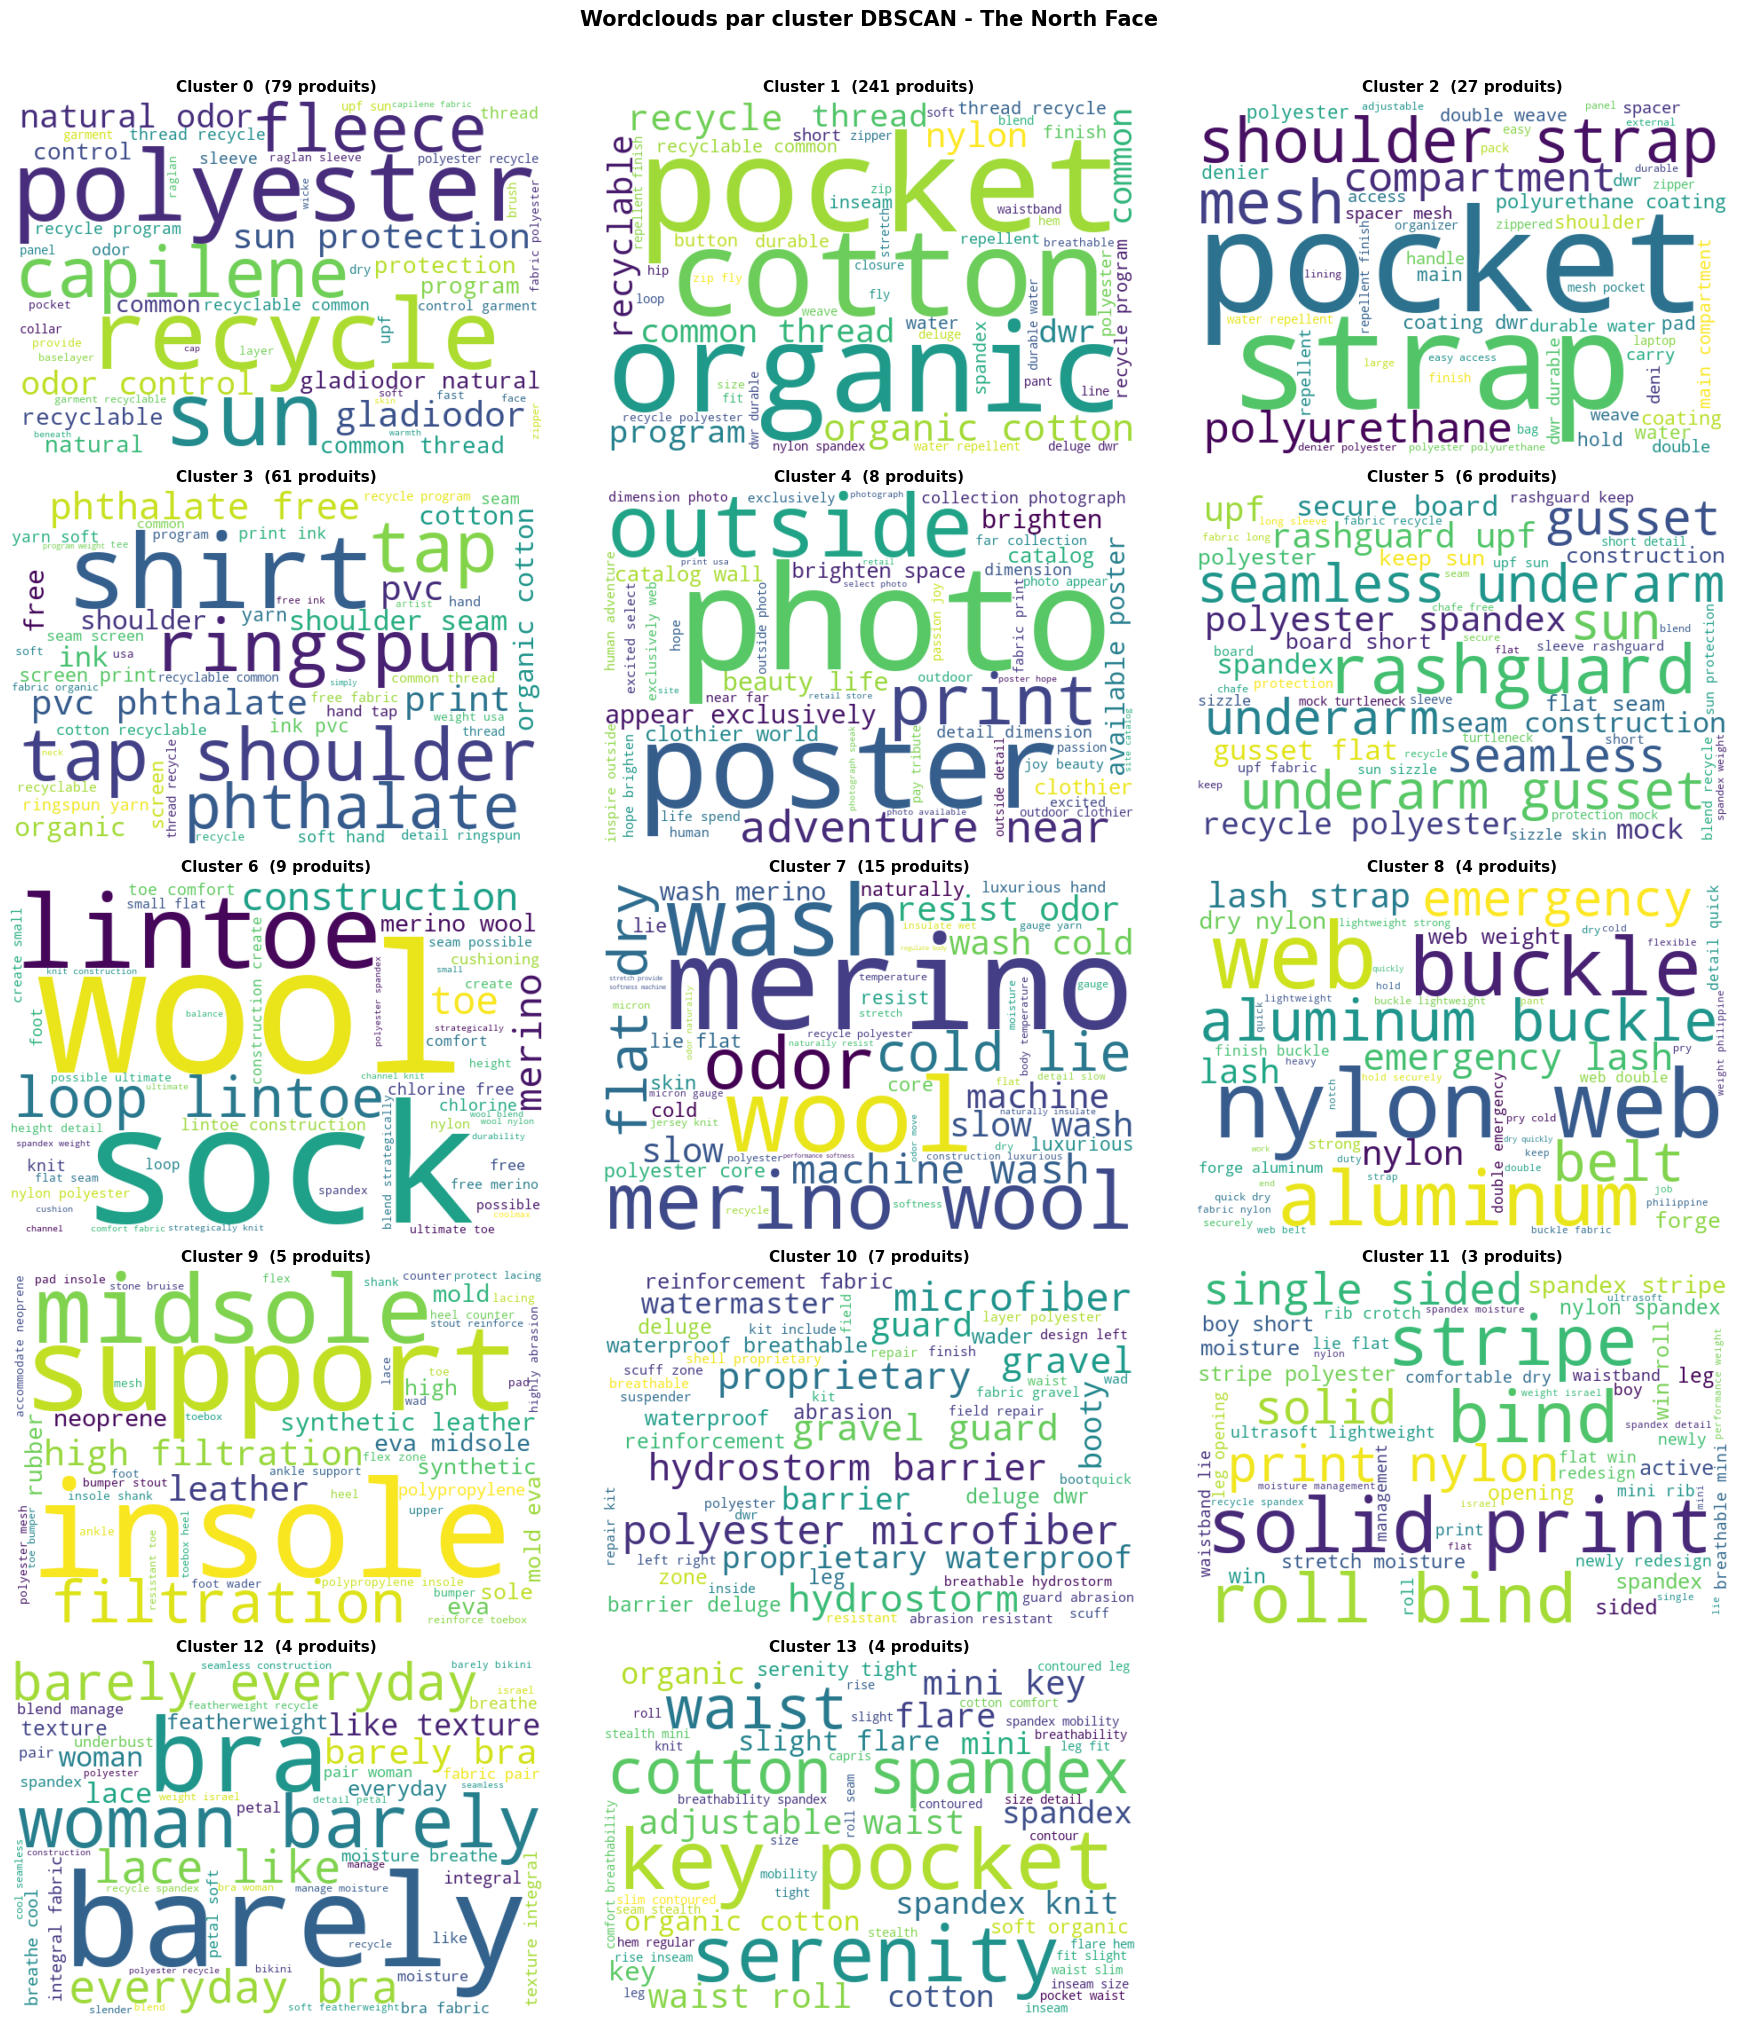

In [ ]:
# Récupération des identifiants de clusters valides (hors outliers)
cluster_ids = sorted([c for c in df['cluster'].unique() if c != -1])

# Récupérer les noms de tous les mots du vectoriseur
feature_names = tfidf.get_feature_names_out()

# Configuration de la grille d'affichage
n_cols = 3
n_rows = (len(cluster_ids) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, cluster_id in enumerate(cluster_ids):
    # Trouver les indices des produits de ce cluster dans le dataframe
    cluster_indices = np.where(df['cluster'] == cluster_id)[0]
    n_products = len(cluster_indices)
    # Extraire la sous-matrice TF-IDF de ces produits et calculer la moyenne par colonne
    cluster_tfidf = tfidf_matrix[cluster_indices]
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=0)).flatten()
    # Créer le dictionnaire {mot: score_tf_idf_moyen}
    word_freq = {
        feature_names[idx]: mean_tfidf[idx]
        for idx in range(len(feature_names))
        if mean_tfidf[idx] > 0
    }
    # Générer le WordCloud avec les scores TF-IDF
    wc = WordCloud(
        width=600,
        height=400,
        background_color='white',
        max_words=50,
        colormap='viridis',
    ).generate_from_frequencies(word_freq)
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].set_title(
        f'Cluster {cluster_id}  ({n_products} produits)',
        fontsize=11, fontweight='bold'
    )
    axes[i].axis('off')

# Masquer les axes inutilisés
for j in range(len(cluster_ids), len(axes)):
    axes[j].axis('off')

plt.suptitle('Wordclouds par cluster DBSCAN - The North Face', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Chaque nuage de mots révèle la thématique dominante d'un cluster. On distingue des groupes sémantiquement cohérents: matières techniques et synthétiques (polyester, capilene, recycle, fleece), bagages et accessoires (pocket, strap, shoulder), chaussettes (wool, sock, merino wool, lintoe), chaussures (support, insole, midsole, filtration), ... 

---
## Partie 2 - Système de recommandation

Le système de recommandation s'appuie sur les clusters identifiés en Partie 1 : **deux produits appartenant au même cluster sont considérés comme similaires**. Pour un produit donné, la fonction `find_similar_items` calcule la similarité cosinus entre ce produit et tous ses voisins du même cluster, puis retourne les 5 les plus proches par ordre décroissant de similarité.

In [13]:
def find_similar_items(item_id, dataframe=df, matrix=tfidf_matrix, n_recommendations=5):
    """
    Retourne les n produits les plus similaires au produit spécifié,
    triés par similarité cosinus décroissante au sein du même cluster.
    Plus la similarité est grande, plus la distance est petite.

    Paramètres
    ----------
    item_id : int
        Identifiant du produit de référence.
    dataframe : pd.DataFrame
        DataFrame contenant les colonnes 'id', 'cluster' et 'description'.
    matrix : sparse matrix
        Matrice TF-IDF utilisée pour calculer la similarité cosinus.
    n_recommendations : int
        Nombre de recommandations à retourner (défaut : 5).

    Retourne
    --------
    list : Liste des identifiants des produits recommandés, triés du plus
           similaire au moins similaire.
    """
    # Vérification que l'identifiant existe dans le catalogue
    if item_id not in dataframe['id'].values:
        print(f'Erreur : le produit {item_id} n\'existe pas dans le catalogue.')
        return []

    # Récupération de la position (index ligne) du produit dans le dataframe
    ref_idx = dataframe.index[dataframe['id'] == item_id][0]

    # Récupération du cluster du produit de référence
    cluster_id = dataframe.loc[ref_idx, 'cluster']

    # Cas où le produit est un outlier (cluster = -1) : aucune recommandation possible
    if cluster_id == -1:
        print(f'Le produit {item_id} est un outlier : aucune recommandation disponible.')
        return []

    # Sélection des indices des produits du même cluster, hors produit de référence
    cluster_mask = (dataframe['cluster'] == cluster_id) & (dataframe['id'] != item_id)
    cluster_indices = dataframe.index[cluster_mask].tolist()

    if not cluster_indices:
        print(f'Aucun autre produit disponible dans le cluster {cluster_id}.')
        return []

    # Calcul de la similarité cosinus entre le produit de référence
    # et tous les produits du même cluster
    ref_vector = matrix[ref_idx]                  # vecteur TF-IDF du produit de référence
    cluster_vectors = matrix[cluster_indices]     # vecteurs TF-IDF des voisins
    similarities = cosine_similarity(ref_vector, cluster_vectors).flatten()

    # Tri des voisins par similarité cosinus décroissante
    sorted_positions = similarities.argsort()[::-1]

    # Sélection des n produits les plus proches
    n = min(n_recommendations, len(cluster_indices))
    top_indices = [cluster_indices[i] for i in sorted_positions[:n]]
    recommended_ids = dataframe.loc[top_indices, 'id'].tolist()

    return recommended_ids


In [14]:
# Test de la fonction sur un produit appartenant à un cluster valide
test_id = df.loc[df['cluster'] != -1, 'id'].iloc[0]
recs = find_similar_items(test_id)

print(f'Produit de référence : ID {test_id}')
print(f'Cluster             : {df.loc[df["id"] == test_id, "cluster"].values[0]}')
print(f'Produits recommandés (triés par similarité cosinus) : {recs}')

# Affichage détaillé : produit de référence et ses recommandations
ref_desc = df.loc[df['id'] == test_id, 'description'].values[0]
print(f'=== Produit consulté - ID {test_id} ===')
print(ref_desc[:250] + '...')
print()

print('=== Vous pourriez également etre intéressé(e) par ===')
for rank, rec_id in enumerate(recs, 1):
    rec_desc = df.loc[df['id'] == rec_id, 'description'].values[0]
    print(f'{rank}. Produit ID {rec_id} : {rec_desc[:180]}...')
    print()

Produit de référence : ID 1
Cluster             : 0
Produits recommandés (triés par similarité cosinus) : [19, 494, 495, 365, 2]
=== Produit consulté - ID 1 ===
Active classic boxers - There's a reason why our boxers are a cult favorite - they keep their cool, especially in sticky situations. The quick-drying, lightweight underwear takes up minimal space in a travel pack. An exposed, brushed waistband offers...

=== Vous pourriez également etre intéressé(e) par ===
1. Produit ID 19 : Cap 1 boxer briefs - On bivy or belay, the form-fitting Capilene 1 Boxer Briefs stay dry and comfortable. Made from 100% recycled polyester, the underwear excels at moisture-wickin...

2. Produit ID 494 : Active boxer briefs - A no-fuss travel companion, these skivvies love sink and creek baths, and they dry in a flash. The quick-wicking underwear breathes exceptionally well, keepin...

3. Produit ID 495 : Active briefs - These featherweight, quick-wicking briefs keep you comfortable and dry whether you tr

In [15]:
# Interface utilisateur interactive
# L'utilisateur saisit un identifiant produit et obtient une liste de produits similaires

print('=================================================')
print('  Système de recommandation - The North Face')
print('=================================================')
print(f'Identifiants disponibles : de {df["id"].min()} à {df["id"].max()}')
print()

try:
    user_input = input('Entrez l\'identifiant du produit qui vous intéresse : ')
    user_id = int(user_input.strip())

    similar_items = find_similar_items(user_id)

    if similar_items:
        # Affichage du produit consulté
        ref_text = df.loc[df['id'] == user_id, 'description'].values[0]
        print(f'\nVous consultez le produit ID {user_id} :')
        print(f'  {ref_text[:220]}...')

        # Affichage des recommandations
        print(f'\nVous pourriez également être intéressé(e) par :')
        for idx, rec_id in enumerate(similar_items, 1):
            rec_text = df.loc[df['id'] == rec_id, 'description'].values[0]
            print(f'  {idx}. Produit ID {rec_id} : {rec_text[:140]}...')

except ValueError:
    print('Erreur : veuillez saisir un nombre entier valide.')
except KeyboardInterrupt:
    print('\nInterruption de la saisie.')

  Système de recommandation - The North Face
Identifiants disponibles : de 1 à 500


Vous consultez le produit ID 13 :
  Beach bucket - Whenever you're at the junction of water and land, neutralize the sun's unforgiving rays with the wide brim and soft design of our versatile Beach Bucket. It has a durable, semi-rigid foam bill that is bla...

Vous pourriez également être intéressé(e) par :
  1. Produit ID 135 : Surf brim - Whether you're paddling back out or waiting on the next set, our Surf Brim keeps your cranium cool and your eyes shaded. It is a...
  2. Produit ID 479 : Bimini cap - South of Kanab, temperatures take a decidedly upward swing. In these sun-exposed landscapes, our Bimini provides a welcome retr...
  3. Produit ID 17 : Bucket hat - Besides its shade-casting prowess, the Bucket provides perfect eye cover after an extra-large fish taco fest. It's made from so...
  4. Produit ID 149 : Velocity cap - When you're running the parched, open slopes of Black Mountain, our Velo

Le système de recommandation fonctionne en trois étapes : 
- identifier le cluster du produit consulté. 
- calculer la similarité cosinus entre ce produit et tous ses voisins de cluster. 
- retourner les 5 produits les plus proches par ordre décroissant de similarité. Le tri cosinus garantit que les recommandations proposées sont toujours les plus pertinentes disponibles. 

Les produits outliers (cluster = -1) ne reçoivent pas de recommandation.

---
## Partie 3 - Modélisation thématique (LSA / TruncatedSVD)

L'Analyse Sémantique Latente (LSA) utilise la décomposition en valeurs singulières tronquée (**TruncatedSVD**) pour extraire des thèmes latents dans le corpus.

Différence clé avec le clustering :
- Le **clustering** assigne chaque produit à un seul groupe.
- La **LSA** projette chaque produit dans un espace multi-thèmes : un même produit peut être associé à plusieurs thèmes simultanément.

In [7]:
# Nombre de thèmes latents à extraire
N_COMPONENTS = 20

# Pipeline LSA : TruncatedSVD suivi d'une normalisation L2
# La normalisation L2 garantit que chaque vecteur document à une norme unitaire,
# ce qui facilite la comparaison entre les représentations de thèmes
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=42)
normalizer = Normalizer(copy=True)
lsa_pipeline = make_pipeline(svd, normalizer)

# Application de la pipeline LSA sur la matrice TF-IDF
# La variable topic_encoded_df contient la matrice document x thèmes
topic_encoded_df = lsa_pipeline.fit_transform(tfidf_matrix)

print(f'Dimensions de la matrice topic_encoded_df : {topic_encoded_df.shape}')
print(f'  - Lignes (produits)       : {topic_encoded_df.shape[0]}')
print(f'  - Colonnes (thèmes latents) : {topic_encoded_df.shape[1]}')

Dimensions de la matrice topic_encoded_df : (500, 20)
  - Lignes (produits)       : 500
  - Colonnes (thèmes latents) : 20


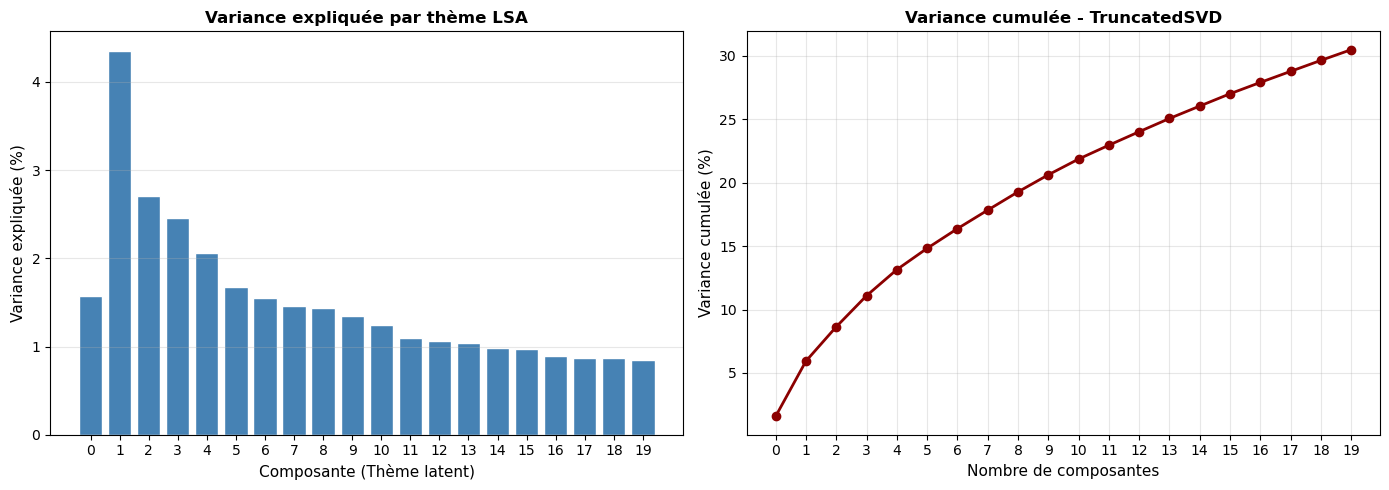

Variance expliquée par 20 composantes : 30.5%

Les valeurs singulières:
 [6.13019604 4.80072539 3.55495092 3.38211643 3.09872687 2.802327
 2.7116034  2.64341881 2.59177508 2.50944234 2.41278585 2.2601768
 2.228741   2.21067074 2.1372504  2.12775908 2.04201699 2.01929284
 2.01145517 1.98450592]


In [ ]:
# Analyse de la variance expliquée par chaque composante SVD
# Cela indique l'importance de chaque thème dans la représentation globale du corpus
explained_variance = svd.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : variance expliquée par composante
ax1.bar(
    range(0, N_COMPONENTS),
    explained_variance * 100,
    color='steelblue',
    edgecolor='white'
)
ax1.set_xlabel('Composante (Thème latent)', fontsize=11)
ax1.set_ylabel('Variance expliquée (%)', fontsize=11)
ax1.set_title('Variance expliquée par thème LSA', fontsize=12, fontweight='bold')
ax1.set_xticks(range(0, N_COMPONENTS))
ax1.grid(axis='y', alpha=0.3)

# Graphique 2 : variance cumulée
ax2.plot(
    range(0, N_COMPONENTS),
    cumulative_variance * 100,
    marker='o',
    color='darkred',
    linewidth=2
)
ax2.set_xlabel('Nombre de composantes', fontsize=11)
ax2.set_ylabel('Variance cumulée (%)', fontsize=11)
ax2.set_title('Variance cumulée - TruncatedSVD', fontsize=12, fontweight='bold')
ax2.set_xticks(range(0, N_COMPONENTS))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'Variance expliquée par {N_COMPONENTS} composantes : {cumulative_variance[-1]*100:.1f}%\n')

print("Les valeurs singulières:\n", svd.singular_values_)

**Remarque :** l'utilisation de TruncatedSVD sur la matrice TF-IDF (dans le cadre de la LSA) ne centre pas la matrice pour des raisons de performance sur les données creuses, ce qui explique ce profil de variance spécifique sur la première composante. Néanmoins, on peut constater que c'est la première composante principale qui la plus grande valeur singulière.

In [17]:
# Extraction du thème principal de chaque document
# Pour chaque produit, on identifie l'indice de la composante de valeur absolue maximale
df['main_topic'] = np.argmax(np.abs(topic_encoded_df), axis=1)

# Distribution des thèmes principaux dans le corpus
topic_distribution = df['main_topic'].value_counts().sort_index()
print('Nombre de produits par thème principal :')
print(topic_distribution.to_string())

Nombre de produits par thème principal :
main_topic
0     174
1      49
2      21
3      26
4      21
5       8
6       8
7      35
8      38
9      21
10     12
11     17
12      7
13     11
14      6
16     10
17     19
18      9
19      8


### Visualisation des thèmes latents - Nuages de mots (Wordclouds)

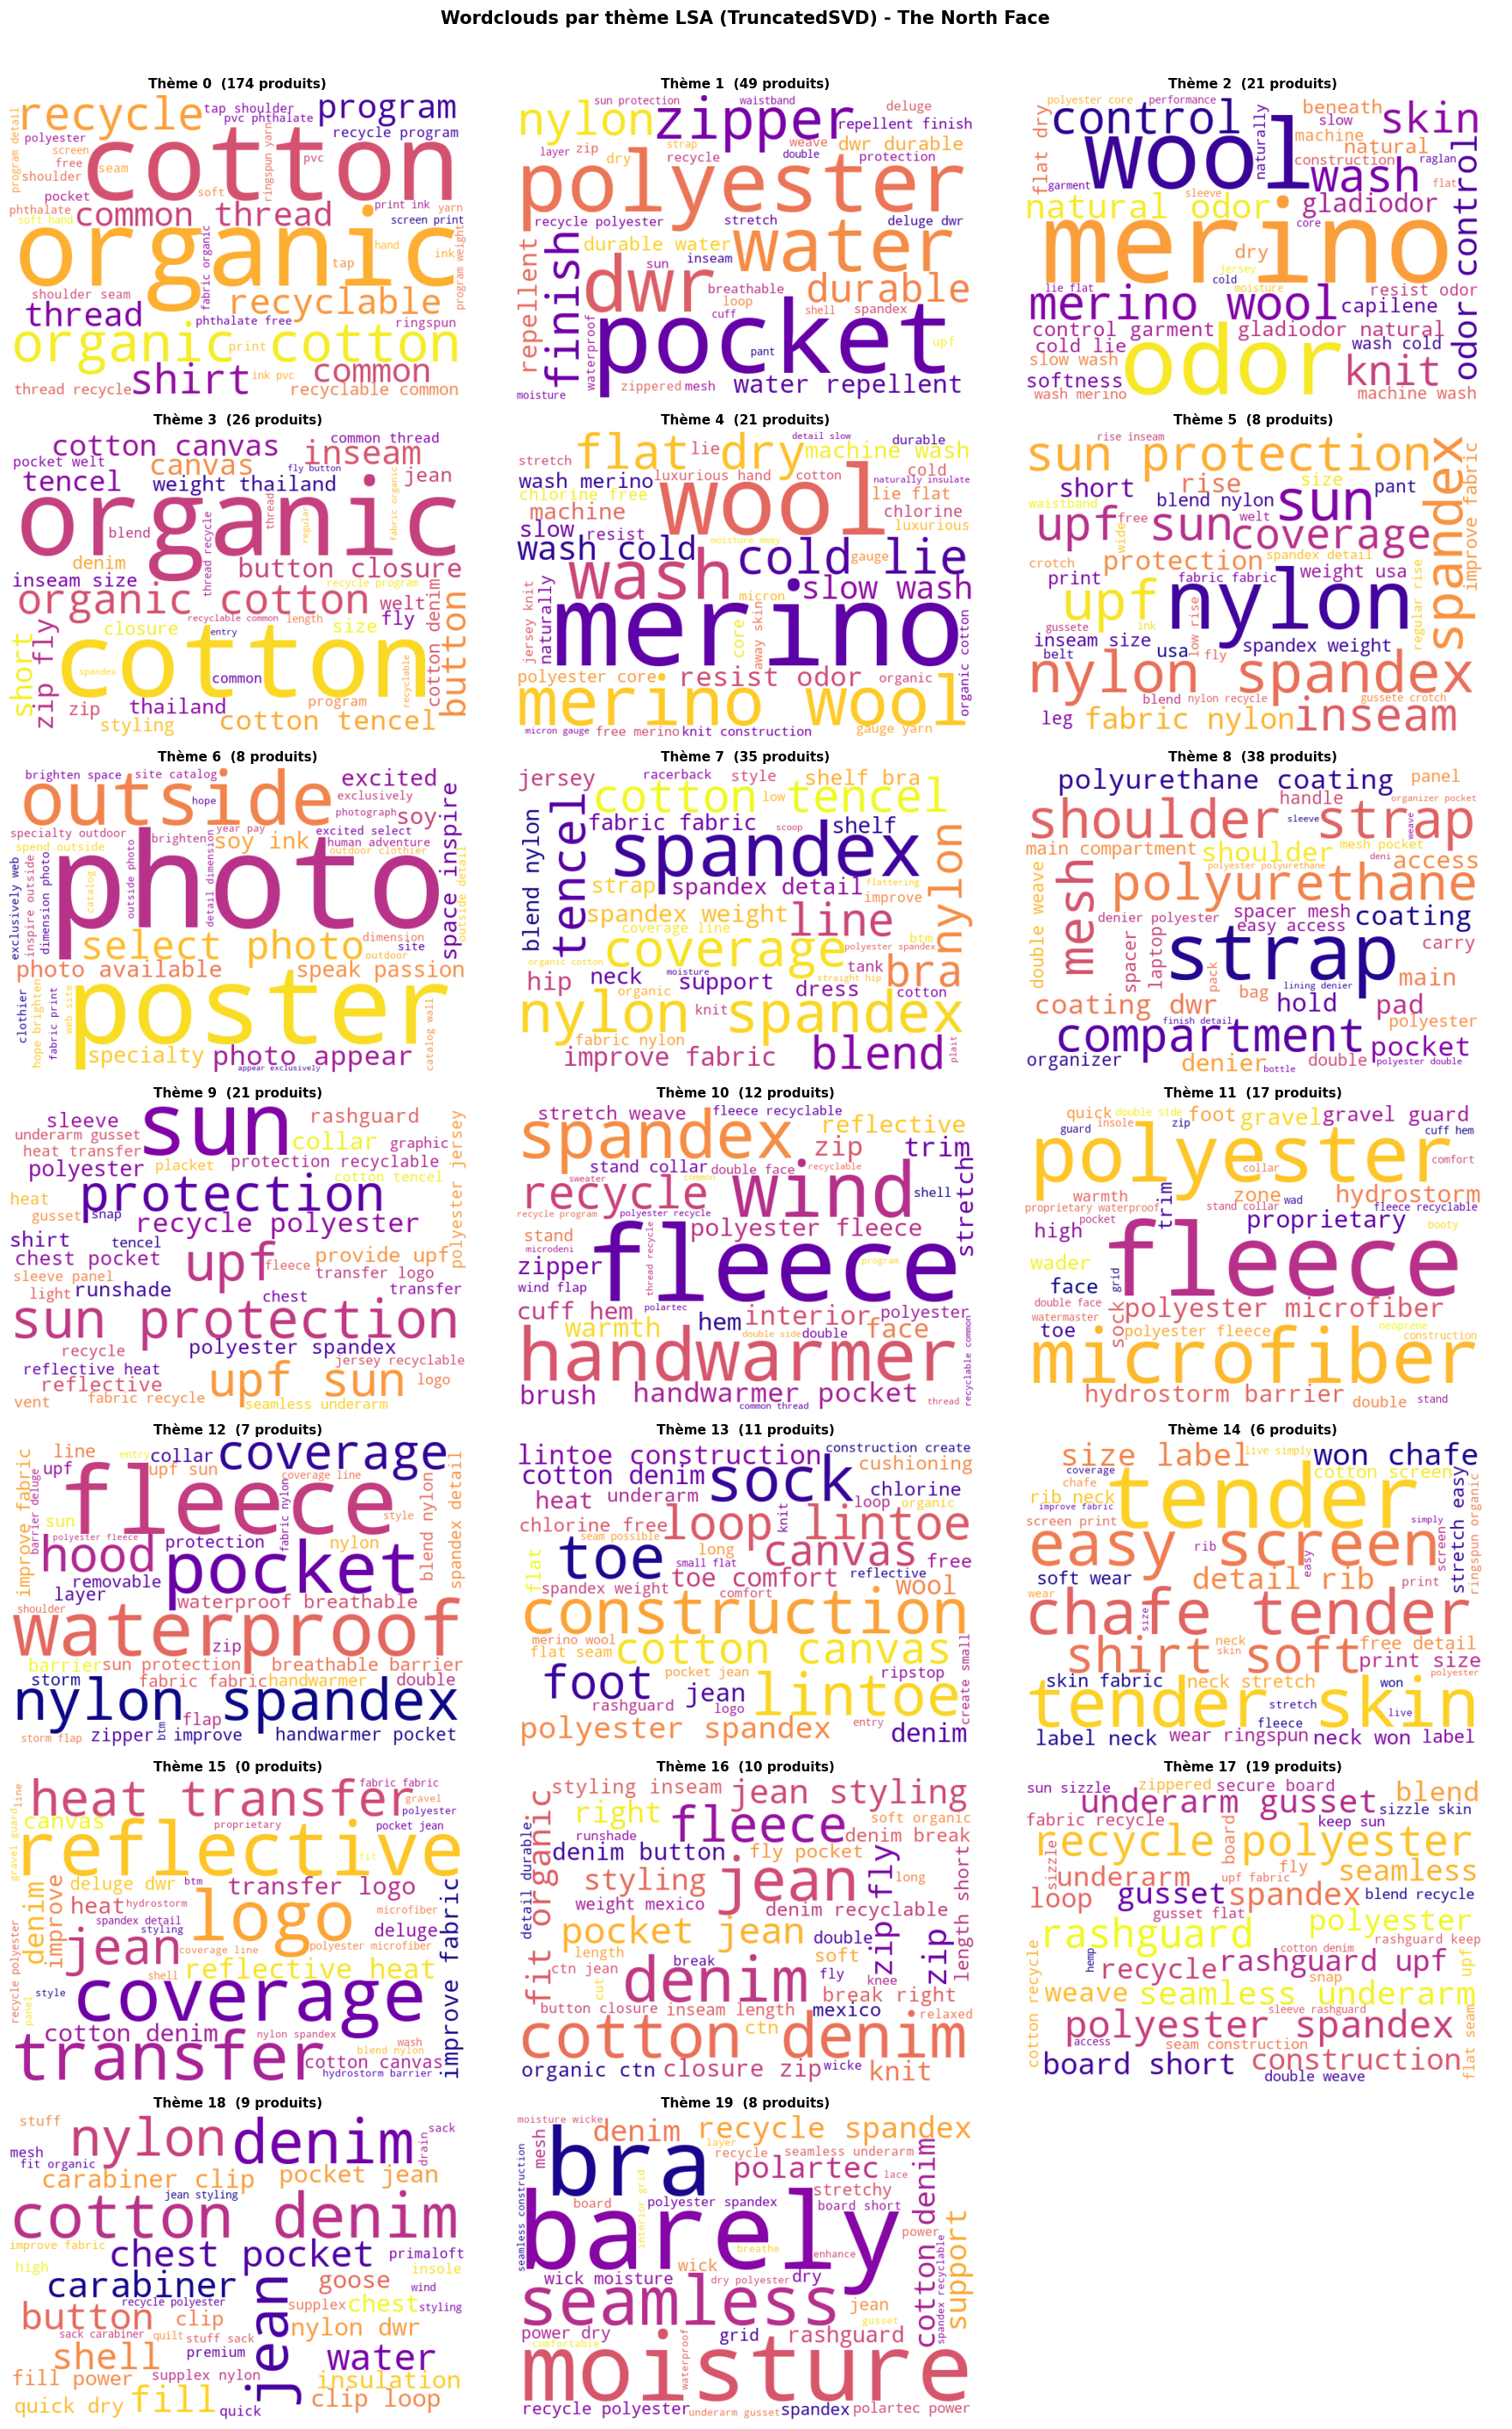

In [ ]:
# Récupération du vocabulaire du vectoriseur TF-IDF
feature_names = tfidf.get_feature_names_out()

def get_top_words_for_topic(topic_idx, svd_model, feature_names, n_words=40):
    """
    Retourne un dictionnaire {mot: poids} pour les n termes les plus
    associes à un thème LSA donné.

    Les composantes SVD (matrice components_) donnent le poids de chaque
    terme du vocabulaire dans chaque thème latent.
    """
    # Vecteur de poids du thème sélectionné (ligne de la matrice components_)
    topic_vector = svd_model.components_[topic_idx]
    # Tri des indices par poids décroissant
    top_indices = topic_vector.argsort()[-n_words:][::-1]
    # Construction du dictionnaire en ne conservant que les poids positifs
    top_words = {
        feature_names[i]: float(topic_vector[i])
        for i in top_indices if topic_vector[i] > 0
    }
    return top_words


# Affichage de la grille de wordclouds pour les N_COMPONENTS thèmes
n_cols = 3
n_rows = (N_COMPONENTS + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for topic_idx in range(N_COMPONENTS):
    top_words = get_top_words_for_topic(topic_idx, svd, feature_names, n_words=40)
    # Nombre de produits pour lesquels ce thème est le thème dominant
    n_docs = len(df[df['main_topic'] == topic_idx])

    if top_words:
        wc = WordCloud(
            width=600,
            height=400,
            background_color='white',
            max_words=40,
            colormap='plasma'
        ).generate_from_frequencies(top_words)

        axes[topic_idx].imshow(wc, interpolation='bilinear')
        axes[topic_idx].set_title(
            f'Thème {topic_idx}  ({n_docs} produits)',
            fontsize=11, fontweight='bold'
        )
    axes[topic_idx].axis('off')

# Masquer les axes inutilisés
for j in range(N_COMPONENTS, len(axes)):
    axes[j].axis('off')

plt.suptitle('Wordclouds par thème LSA (TruncatedSVD) - The North Face', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [22]:
# Résumé textuel : affichage des 10 mots-clés de chaque thème pour une lecture rapide
print('=== Mots-clés par thème LSA ===\n')
for topic_idx in range(N_COMPONENTS):
    top_words = get_top_words_for_topic(topic_idx, svd, feature_names, n_words=10)
    words_str = ', '.join(list(top_words.keys())[:10])
    n_docs = len(df[df['main_topic'] == topic_idx])
    print(f'Thème {topic_idx:2d} ({n_docs:3d} produits) : {words_str}')

=== Mots-clés par thème LSA ===

Thème  0 (174 produits) : organic, cotton, organic cotton, recycle, shirt, recyclable, common thread, common, program, thread
Thème  1 ( 49 produits) : pocket, polyester, dwr, water, zipper, nylon, finish, durable, water repellent, repellent
Thème  2 ( 21 produits) : merino, wool, odor, merino wool, control, wash, skin, knit, natural odor, odor control
Thème  3 ( 26 produits) : organic, cotton, organic cotton, button, inseam, short, cotton canvas, canvas, tencel, cotton tencel
Thème  4 ( 21 produits) : merino, wool, merino wool, wash, flat dry, cold lie, wash cold, slow wash, resist odor, machine wash
Thème  5 (  8 produits) : nylon, nylon spandex, sun, upf, spandex, sun protection, upf sun, inseam, coverage, fabric nylon
Thème  6 (  8 produits) : photo, poster, outside, select photo, photo appear, photo available, soy, soy ink, excited, space inspire
Thème  7 ( 35 produits) : spandex, nylon spandex, coverage, tencel, cotton tencel, line, blend, nylon, 

L'analyse LSA révèle des thèmes sémantiques latents qui correspondent à des catégories fonctionnelles du catalogue : matériaux techniques (polyester, spandex, recycle), usage (sun, sun protection, upf, protection), type de produit (construction, sock, toe, lintoe, foot), caractéristiques (waterproof, breathable, repellent), etc.

---
## Synthèse et conclusions

Ce projet a exploré le catalogue de produits The North Face à travers trois axes complémentaires :

**Partie 1 - Clustering DBSCAN :**
L'algorithme a identifié des clusters cohérents. La lemmatisation spaCy, combinée à la distance cosinus et au TF-IDF, produit une segmentation sémantiquement pertinente. Les wordclouds confirment la cohérence de chaque cluster (sous-vêtements, matériaux, chaussures, sacs, ...).

**Partie 2 - Système de recommandation :**
La fonction propose les 5 produits les plus similaires au sein du même cluster, triés par similarité cosinus décroissante. Cette approche est plus précise qu'un tirage aléatoire et constitue une base solide pour une section "Vous pourriez également aimer" sur le site e-commerce.

**Partie 3 - Modélisation thématique LSA :**
TruncatedSVD a extrait 20 thèmes latents dans le corpus. Cette approche est complémentaire au clustering car elle permet une représentation multi-thèmes de chaque produit, plus nuancée et utile pour réorganiser les catégories de navigation du catalogue.